# Notebook 15: Task aggregation and coverage sensitivity

Addresses three reviewer points about how the 37 tasks were grouped and which were used:

| Point | Request |
|---|---|
| **R1.5** | Justify the lobe-based grouping and discuss the influence of the unequal task counts per category |
| **R1.6** | The tensor decomposition does not reproduce the full sex association, particularly Component 4 |
| **R2.1** | The tensor uses 28 individual tasks rather than the 5 categories, with 9 tasks excluded and not listed; say how far the finding depends on features, rank or method |

## The confound this notebook removes

The matrix decomposition uses all 37 tasks aggregated into five lobe categories. The tensor
decomposition retains the task dimension but required complete participant coverage, which
nine tasks lack, so it uses 28. A component that carries the sex association in one and not
the other may differ because of **the decomposition** or because of **the nine missing
tasks**, and the submitted manuscript cannot separate these. Two refits separate them:

- **`t28_pooled`** — the published pipeline exactly, but restricted to the 28 tasks: samples
  from the retained tasks are pooled within each category and the median taken. Differs from
  the published solution *only* in task coverage, so it isolates the coverage effect.
- **`t28_taskmedian`** — per-task medians first, then the median across the retained tasks
  within each category. This matches the tensor's own inputs, which are per-task medians, so
  comparing it with the tensor isolates the decomposition.

Together they say which of the two explanations holds.

## The aggregation sensitivity for R1.5

- **`noocc`** — the occipital category, which contains a single task, dropped entirely. The
  feature space falls from 350 to 280.
- **`bal_*`** — equal task counts per category by random subsampling, repeated over several
  draws so the result does not rest on one draw. This is the direct test of whether the
  unequal counts (6, 6, 1, 9, 15) shape the components.

Note on what unequal counts can and cannot do: because aggregation is by median within
category, every category contributes exactly 70 features regardless of how many tasks it
holds, so the temporal category's 15 tasks carry no more weight in the decomposition than
the occipital category's one. What differs is the precision of each median. The balanced
refits test that residual concern.

## Inputs

Raw: `data/eeg_features/BA*/2_emotiv_fft_values.csv`, `data/stimuli.csv`
Earlier outputs: `feature_matrix.csv`, `feature_matrix_raw.csv`, `metadata.csv`,
`nmf_H.csv`, `nmf_W.csv`, `posthoc_per_component.csv`, `omnibus_results.csv`,
`parafac_factors_channels.csv`, `parafac_factors_bands.csv`

## Outputs

CSVs: `nb15_coverage.csv`, `nb15_scenario_components.csv`, `nb15_scenario_sex.csv`,
`nb15_parafac_correspondence.csv`, `nb15_balanced_draws.csv`
Figures: `nb15_fig_scenarios.png`, `nb15_fig_parafac.png` — 300 dpi
Summary: `nb15_summary.txt`

## Setup

In [1]:
import re
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from scipy.optimize import linear_sum_assignment
from sklearn.decomposition import NMF
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore")

PROJECT_ROOT = Path(".").resolve().parent
DATA_DIR = PROJECT_ROOT / "data"
EEG_DIR = DATA_DIR / "eeg_features"
OUTPUT_DIR = PROJECT_ROOT / "outputs"

RAW_FILENAME = "2_emotiv_fft_values.csv"

CHANNELS = ["AF3", "F7", "F3", "FC5", "T7", "P7", "O1",
            "O2", "P8", "T8", "FC6", "F4", "F8", "AF4"]
FREQ_BANDS = ["Theta", "Alpha", "BetaL", "BetaH", "Gamma"]
POW_COLS = [f"POW.{ch}.{band}" for ch in CHANNELS for band in FREQ_BANDS]

# --- NMF settings: identical to Notebook 02 ---
MAX_ITER = 500
TOL = 1e-4
RANDOM_SEED_BASE = 42
N_INIT_FULL = 50
PUBLISHED_K = 5

# --- Winsorisation percentiles: must match Notebook 01 ---
LOWER_PCT, UPPER_PCT = 2.5, 97.5

# --- Omnibus settings: identical to Notebook 04 ---
N_PERMUTATIONS = 5000
FDR_ALPHA = 0.05
PERM_SEED = 42

# --- Balanced-category refits ---
N_BALANCED_DRAWS = 10
BALANCE_SEED = 2026
# Categories with fewer tasks than the balanced count are dropped from those refits;
# set BALANCE_EXCLUDE to the categories that cannot support it (the single-task one).
BALANCE_EXCLUDE = ["occipital"]

SEX_COL = "Gender"

print(f"Balanced refits: {N_BALANCED_DRAWS} draws, excluding categories {BALANCE_EXCLUDE}")
print()
print("Expected runtime: the raw pass is roughly 3-8 min; each scenario then costs one")
print("50-initialisation NMF fit plus one 17-variable permutation screen, roughly 5-15 min")
print("apiece. With the balanced draws reported on the sex variable only, budget 1-2 hours")
print("for the whole notebook.")

Balanced refits: 10 draws, excluding categories ['occipital']

Expected runtime: the raw pass is roughly 3-8 min; each scenario then costs one
50-initialisation NMF fit plus one 17-variable permutation screen, roughly 5-15 min
apiece. With the balanced draws reported on the sex variable only, budget 1-2 hours
for the whole notebook.


## Load earlier outputs

In [2]:
feature_matrix = pd.read_csv(OUTPUT_DIR / "feature_matrix.csv", index_col="participant_id")
feature_matrix_raw = pd.read_csv(OUTPUT_DIR / "feature_matrix_raw.csv", index_col="participant_id")
feature_matrix_raw = feature_matrix_raw.loc[feature_matrix.index, feature_matrix.columns]
metadata = (pd.read_csv(OUTPUT_DIR / "metadata.csv")
            .set_index("participant_id")
            .reindex(feature_matrix.index))
H_ref = pd.read_csv(OUTPUT_DIR / "nmf_H.csv", index_col=0)
W_ref = pd.read_csv(OUTPUT_DIR / "nmf_W.csv", index_col="participant_id")
stimuli = pd.read_csv(DATA_DIR / "stimuli.csv")

COMP_LABELS = list(H_ref.index)
PIDS = feature_matrix.index.to_numpy()
N = len(PIDS)

raw_sex = metadata[SEX_COL].astype(str).str.strip().str.upper().str[0]
if not set(raw_sex.dropna().unique()) <= {"M", "F"}:
    raise ValueError(f"Could not read {SEX_COL!r} as M/F: "
                     f"{sorted(metadata[SEX_COL].dropna().unique())}")
SEX = raw_sex.values

PUBLISHED_EFFECTS = pd.read_csv(OUTPUT_DIR / "posthoc_per_component.csv")
PUBLISHED_EFFECTS = (PUBLISHED_EFFECTS[PUBLISHED_EFFECTS["variable"] == SEX_COL]
                     .set_index("component"))
PUB_OMNIBUS = pd.read_csv(OUTPUT_DIR / "omnibus_results.csv")
PUB_SEX_STAT = float(PUB_OMNIBUS[PUB_OMNIBUS["variable"] == SEX_COL].iloc[0]["observed_stat"])


def to_cat_key(lobe_str):
    """Sanitise a lobe label into a column prefix, as in Notebook 01."""
    return lobe_str.strip().lower().replace("-", "_").replace(" ", "_")


stimuli["category"] = stimuli["primary_lobe_targeted"].map(to_cat_key)
TASK_TO_CATEGORY = dict(zip(stimuli["original_stimuli_name"].astype(str), stimuli["category"]))
TASKS_ALL = stimuli["original_stimuli_name"].astype(str).tolist()
CATEGORIES = sorted(stimuli["category"].unique())

print(f"{N} participants, {len(TASKS_ALL)} tasks, {len(CATEGORIES)} categories")
for cat in CATEGORIES:
    tasks = [t for t in TASKS_ALL if TASK_TO_CATEGORY[t] == cat]
    print(f"  {cat}: {len(tasks)} tasks")

86 participants, 37 tasks, 5 categories
  frontal: 6 tasks
  frontal_central: 6 tasks
  occipital: 1 tasks
  parietal: 9 tasks
  temporal: 15 tasks


## Shared helper functions

Reproduced from notebooks 01, 02, 04 and 05 so every statistic stays comparable.

In [3]:
def preprocess_array(raw, fit_rows=None, lower_pct=LOWER_PCT, upper_pct=UPPER_PCT):
    """Notebook 01 transform: log1p -> winsorise -> min-max to [0, 1]."""
    logged = np.log1p(np.asarray(raw, dtype=float))
    fit = logged if fit_rows is None else logged[fit_rows]
    lo = np.percentile(fit, lower_pct, axis=0)
    hi = np.percentile(fit, upper_pct, axis=0)
    wins = np.clip(logged, lo, hi)
    wins_fit = wins if fit_rows is None else wins[fit_rows]
    fmin, fmax = wins_fit.min(axis=0), wins_fit.max(axis=0)
    span = fmax - fmin
    span[span == 0] = 1.0
    return np.clip((wins - fmin) / span, 0.0, 1.0)


def cosine_similarity_matrix(A, B):
    """Pairwise cosine similarity between rows of A and rows of B."""
    A_norm = A / (np.linalg.norm(A, axis=1, keepdims=True) + 1e-12)
    B_norm = B / (np.linalg.norm(B, axis=1, keepdims=True) + 1e-12)
    return A_norm @ B_norm.T


def match_to_reference(H_new, H_ref_arr):
    """Hungarian-match rows of H_new to rows of H_ref_arr."""
    sim = cosine_similarity_matrix(H_ref_arr, H_new)
    row, col = linear_sum_assignment(-sim)
    cos = np.full(H_ref_arr.shape[0], np.nan)
    idx = np.full(H_ref_arr.shape[0], -1, dtype=int)
    cos[row] = sim[row, col]
    idx[row] = col
    return cos, idx


def fit_nmf_best(X, k, n_init, seed_base):
    """Fit NMF n_init times and return the lowest-error solution, as in Notebook 02."""
    best = None
    for i in range(n_init):
        model = NMF(n_components=k, init="random", random_state=seed_base + i,
                    max_iter=MAX_ITER, tol=TOL, beta_loss="frobenius", solver="cd")
        W = model.fit_transform(X)
        if best is None or model.reconstruction_err_ < best[2]:
            best = (W, model.components_, model.reconstruction_err_)
    return best


def rb_female_higher(values, sex_arr):
    """Mann-Whitney rank-biserial and p; positive means higher in female participants."""
    values = np.asarray(values, dtype=float)
    f = values[np.asarray(sex_arr) == "F"]
    m = values[np.asarray(sex_arr) == "M"]
    if len(f) < 3 or len(m) < 3:
        return np.nan, np.nan
    if np.allclose(values, values[0]):
        return 0.0, 1.0
    u, p = stats.mannwhitneyu(m, f, alternative="two-sided")
    return float(1 - (2 * u) / (len(m) * len(f))), float(p)


def make_logreg():
    """LogisticRegression, tolerating the removal of multi_class in newer scikit-learn."""
    try:
        return LogisticRegression(max_iter=2000, multi_class="auto", solver="lbfgs")
    except TypeError:
        return LogisticRegression(max_iter=2000, solver="lbfgs")


def log_likelihood_logistic(model, X, y):
    """Log-likelihood of a fitted logistic model."""
    proba = np.clip(model.predict_proba(X), 1e-12, 1 - 1e-12)
    if proba.shape[1] == 2:
        return np.sum(y * np.log(proba[:, 1]) + (1 - y) * np.log(proba[:, 0]))
    ll = 0.0
    for cls_idx, cls in enumerate(model.classes_):
        ll += np.sum(np.log(proba[y == cls, cls_idx]))
    return ll


def compute_statistic_classification(X, y):
    """McFadden pseudo-R-squared."""
    if len(np.unique(y)) < 2:
        return np.nan
    try:
        full = make_logreg().fit(X, y)
        ll_full = log_likelihood_logistic(full, X, y)
    except Exception:
        return np.nan
    _, counts = np.unique(y, return_counts=True)
    priors = counts / counts.sum()
    ll_null = sum(c * np.log(p) for c, p in zip(counts, priors))
    if ll_null == 0:
        return np.nan
    return 1 - (ll_full / ll_null)


def compute_statistic(X, y, vtype):
    """Dispatch to the statistic matching the variable's measurement scale."""
    if vtype == "continuous":
        return LinearRegression().fit(X, y).score(X, y)
    if vtype in ("binary", "multi"):
        return compute_statistic_classification(X, y)
    raise ValueError(f"Unknown vtype: {vtype}")


VAR_TYPES = {
    "Age":                               "continuous",
    "Gender":                            "binary",
    "Residential Area (Urban/Rural)":    "binary",
    "From City":                         "binary",
    "Single/NotSingle":                  "binary",
    "Education":                         "multi",
    "Field of Study":                    "multi",
    "Occupation":                        "multi",
    "# of LanguagesSpeak":               "continuous",
    "UsedToDoSport":                     "binary",
    "NowDoingSports_aWeek":              "continuous",
    "PlayingAnInstrument":               "binary",
    "History of Neurological Disorders": "binary",
    "Medication Usage":                  "binary",
    "Average Sleep Hours per Night":     "continuous",
    "Smoking (0,1,2,3)":                 "continuous",
    "Alchocol (0,1,2,3)":                "continuous",
}
VAR_TYPES = {v: t for v, t in VAR_TYPES.items() if v in metadata.columns}


def omnibus_screen(W_mat, n_perm, seed, variables=None):
    """Notebook 04's omnibus screen. variables=None screens all; a list screens a subset
    without FDR correction, for the balanced draws where only sex is of interest."""
    rng = np.random.default_rng(seed)
    W_std = StandardScaler().fit_transform(W_mat)
    use = VAR_TYPES if variables is None else {v: VAR_TYPES[v] for v in variables}
    rows = []
    for var, vtype in use.items():
        sub = pd.DataFrame({"y": metadata[var].values})
        sub["idx"] = np.arange(len(sub))
        sub = sub.dropna()
        if len(sub) < 10:
            rows.append({"variable": var, "type": vtype, "n": len(sub),
                         "observed_stat": np.nan, "p_perm": np.nan})
            continue
        X_use = W_std[sub["idx"].values]
        y_raw = sub["y"].values
        if vtype != "continuous":
            y_use, _ = pd.factorize(y_raw)
        else:
            y_num = pd.to_numeric(y_raw, errors="coerce")
            valid = ~pd.isna(y_num)
            if valid.sum() < 10:
                rows.append({"variable": var, "type": vtype, "n": int(valid.sum()),
                             "observed_stat": np.nan, "p_perm": np.nan})
                continue
            X_use = X_use[valid]
            y_use = np.asarray(y_num[valid], dtype=float)
        obs = compute_statistic(X_use, y_use, vtype)
        if np.isnan(obs):
            rows.append({"variable": var, "type": vtype, "n": len(y_use),
                         "observed_stat": np.nan, "p_perm": np.nan})
            continue
        null = np.zeros(n_perm)
        y_perm = np.array(y_use, copy=True)
        for i in range(n_perm):
            rng.shuffle(y_perm)
            null[i] = compute_statistic(X_use, y_perm, vtype)
        rows.append({"variable": var, "type": vtype, "n": len(y_use), "observed_stat": obs,
                     "null_mean": float(np.mean(null)),
                     "p_perm": (np.sum(null >= obs) + 1) / (n_perm + 1)})
    out = pd.DataFrame(rows)
    out["p_fdr"] = np.nan
    out["significant_fdr"] = False
    if variables is None:
        ok = out["p_perm"].notna()
        if ok.any():
            reject, p_fdr, _, _ = multipletests(out.loc[ok, "p_perm"].values,
                                                alpha=FDR_ALPHA, method="fdr_bh")
            out.loc[ok, "p_fdr"] = p_fdr
            out.loc[ok, "significant_fdr"] = reject
    return out.sort_values("p_perm")


print(f"{len(VAR_TYPES)} metadata variables available")

17 metadata variables available


## Part A — Coverage audit and scenario definition

Coverage is recomputed from the raw files rather than assumed, so the 28-task set is the one
the tensor analysis actually used. The nine excluded tasks are named here for the Methods.

In [4]:
def ba_sort_key(p):
    """Sort BA folders numerically, as in Notebook 01."""
    m = re.match(r"BA(\d+)", p.name)
    return int(m.group(1)) if m else 99999


participant_folders = sorted(
    [p for p in EEG_DIR.iterdir() if p.is_dir() and re.match(r"BA\d+", p.name)],
    key=ba_sort_key,
)
participant_folders = [p for p in participant_folders if p.name in set(PIDS)]
print(f"{len(participant_folders)} participant folders matching the analytic sample")

coverage = {t: 0 for t in TASKS_ALL}
t0 = time.time()
for folder in participant_folders:
    tasks_present = set(pd.read_csv(folder / RAW_FILENAME, usecols=["task_name"])["task_name"])
    for t in TASKS_ALL:
        if t in tasks_present:
            coverage[t] += 1
print(f"Coverage audit done in {time.time() - t0:.0f}s")

cov_df = pd.DataFrame({"task": TASKS_ALL,
                       "category": [TASK_TO_CATEGORY[t] for t in TASKS_ALL],
                       "n_participants": [coverage[t] for t in TASKS_ALL]})
cov_df["complete"] = cov_df["n_participants"] == N
cov_df.to_csv(OUTPUT_DIR / "nb15_coverage.csv", index=False)

TASKS_28 = [t for t in TASKS_ALL if coverage[t] == N]
TASKS_EXCLUDED = [t for t in TASKS_ALL if coverage[t] < N]

print()
print(f"Fully covered tasks: {len(TASKS_28)} | incomplete: {len(TASKS_EXCLUDED)}")
print()
print("Tasks excluded from the tensor analysis, for the Methods:")
print(cov_df[~cov_df["complete"]].sort_values("n_participants").to_string(index=False))
print()
print("Retained tasks per category in the 28-task set:")
for cat in CATEGORIES:
    all_c = [t for t in TASKS_ALL if TASK_TO_CATEGORY[t] == cat]
    keep_c = [t for t in TASKS_28 if TASK_TO_CATEGORY[t] == cat]
    print(f"  {cat}: {len(keep_c)}/{len(all_c)}")

86 participant folders matching the analytic sample
Coverage audit done in 8s

Fully covered tasks: 28 | incomplete: 9

Tasks excluded from the tensor analysis, for the Methods:
                          task category  n_participants  complete
temporal_how_many_instruments1 temporal              82     False
                parietal_2d_3d parietal              84     False
temporal_how_many_instruments2 temporal              84     False
                   prefrontal1  frontal              85     False
          parietal_next_in_seq parietal              85     False
                   prefrontal2  frontal              85     False
temporal_how_many_instruments3 temporal              85     False
temporal_how_many_instruments4 temporal              85     False
              image_happy_cute temporal              85     False

Retained tasks per category in the 28-task set:
  frontal: 4/6
  frontal_central: 6/6
  occipital: 1/1
  parietal: 7/9
  temporal: 10/15


In [5]:
rng_bal = np.random.default_rng(BALANCE_SEED)
balance_categories = [c for c in CATEGORIES if c not in BALANCE_EXCLUDE]
tasks_per_cat = {c: [t for t in TASKS_ALL if TASK_TO_CATEGORY[t] == c] for c in CATEGORIES}
BALANCE_N = min(len(tasks_per_cat[c]) for c in balance_categories)
print(f"Balanced refits use {BALANCE_N} tasks per category across "
      f"{len(balance_categories)} categories: {balance_categories}")

SCENARIOS = {
    "full": {"tasks": TASKS_ALL, "mode": "pooled", "categories": CATEGORIES},
    "t28_pooled": {"tasks": TASKS_28, "mode": "pooled", "categories": CATEGORIES},
    "t28_taskmedian": {"tasks": TASKS_28, "mode": "taskmedian", "categories": CATEGORIES},
    "noocc": {"tasks": [t for t in TASKS_ALL if TASK_TO_CATEGORY[t] not in BALANCE_EXCLUDE],
              "mode": "pooled", "categories": balance_categories},
}
for d in range(N_BALANCED_DRAWS):
    picked = []
    for c in balance_categories:
        picked.extend(rng_bal.choice(tasks_per_cat[c], size=BALANCE_N, replace=False).tolist())
    SCENARIOS[f"bal_{d}"] = {"tasks": picked, "mode": "pooled",
                             "categories": balance_categories}

print(f"{len(SCENARIOS)} scenarios defined: "
      f"{[k for k in SCENARIOS if not k.startswith('bal_')]} + "
      f"{N_BALANCED_DRAWS} balanced draws")

Balanced refits use 6 tasks per category across 4 categories: ['frontal', 'frontal_central', 'parietal', 'temporal']
14 scenarios defined: ['full', 't28_pooled', 't28_taskmedian', 'noocc'] + 10 balanced draws


## Part B — One raw pass building every scenario matrix

`pooled` pools the samples of the retained tasks within each category and takes the median,
which is what the published pipeline does. `taskmedian` takes each task's median first and
then the median across tasks within the category, which is what the tensor's inputs are.
The distinction matters because pooling weights a task by its number of samples.

In [6]:
scenario_rows = {name: {} for name in SCENARIOS}
t0 = time.time()
for n_done, folder in enumerate(participant_folders, start=1):
    pid = folder.name
    df = pd.read_csv(folder / RAW_FILENAME)
    missing = [c for c in POW_COLS + ["task_name"] if c not in df.columns]
    if missing:
        raise ValueError(f"{pid}: missing columns {missing[:5]}")
    df = df[df["task_name"].isin(TASK_TO_CATEGORY)].copy()
    df["category"] = df["task_name"].map(TASK_TO_CATEGORY)

    task_medians = df.groupby(["category", "task_name"])[POW_COLS].median()

    for name, spec in SCENARIOS.items():
        keep = set(spec["tasks"])
        if spec["mode"] == "pooled":
            sub = df[df["task_name"].isin(keep)]
            agg = sub.groupby("category")[POW_COLS].median()
        else:
            sub = task_medians[task_medians.index.get_level_values("task_name").isin(keep)]
            agg = sub.groupby(level="category")[POW_COLS].median()
        agg = agg.reindex(spec["categories"])
        flat = agg.stack()
        flat.index = [f"{cat}__{feat}" for cat, feat in flat.index]
        scenario_rows[name][pid] = flat
    if n_done % 20 == 0:
        print(f"  {n_done}/{len(participant_folders)} participants ({time.time() - t0:.0f}s)")

print()
print(f"Raw pass done in {time.time() - t0:.0f}s")

scenario_matrices = {}
for name in SCENARIOS:
    mat = pd.DataFrame(scenario_rows[name]).T
    mat.index.name = "participant_id"
    mat = mat.reindex(PIDS)
    scenario_matrices[name] = mat
    print(f"  {name}: {mat.shape}, missing cells {int(mat.isna().sum().sum())}")

  20/86 participants (7s)
  40/86 participants (12s)
  60/86 participants (17s)
  80/86 participants (22s)

Raw pass done in 23s
  full: (86, 350), missing cells 0
  t28_pooled: (86, 350), missing cells 0
  t28_taskmedian: (86, 350), missing cells 0
  noocc: (86, 280), missing cells 0
  bal_0: (86, 280), missing cells 0
  bal_1: (86, 280), missing cells 0
  bal_2: (86, 280), missing cells 0
  bal_3: (86, 280), missing cells 0
  bal_4: (86, 280), missing cells 0
  bal_5: (86, 280), missing cells 0
  bal_6: (86, 280), missing cells 0
  bal_7: (86, 280), missing cells 0
  bal_8: (86, 280), missing cells 0
  bal_9: (86, 280), missing cells 0


In [7]:
full = scenario_matrices["full"].reindex(columns=feature_matrix_raw.columns)
dev = np.nanmax(np.abs(full.values - feature_matrix_raw.values))
print(f"Sanity check, 'full' scenario against feature_matrix_raw.csv: max deviation {dev:.3e}")
if dev > 1e-6:
    print()
    print("WARNING: the rebuilt full matrix does not match the saved one. The scenario refits")
    print("below are then not comparable with the published solution, and the cause must be")
    print("found before the results are used. Check the category mapping and the aggregation.")
else:
    print("The raw pass reproduces the published feature matrix.")

Sanity check, 'full' scenario against feature_matrix_raw.csv: max deviation 7.105e-15
The raw pass reproduces the published feature matrix.


## Part C — Refit and test each scenario

For each scenario: preprocess with the published transform, fit at k = 5 with the same 50
initialisations, Hungarian-match to the published components over the feature columns the
two share, then run the omnibus screen and the per-component sex follow-up.

For `noocc` and the balanced draws the feature space is a subset of the published one, so the
published H is restricted to the shared columns before matching. A cosine computed over 280
of 350 features is not identical to one over all 350, and the table records which it is.

In [8]:
comp_rows, sex_rows = [], []
main_scenarios = [k for k in SCENARIOS if not k.startswith("bal_")]

for name in main_scenarios:
    spec = SCENARIOS[name]
    mat = scenario_matrices[name]
    if mat.isna().any().any():
        print(f"=== {name}: dropping {int(mat.isna().any(axis=1).sum())} participants with "
              f"missing cells ===")
        mat = mat.dropna(axis=0, how="any")
    shared = [c for c in mat.columns if c in H_ref.columns]
    H_sub = H_ref[shared].values
    X = preprocess_array(mat[shared].values)
    sex_s = SEX[[int(np.where(PIDS == p)[0][0]) for p in mat.index]]

    W_s, H_s, err_s = fit_nmf_best(X, PUBLISHED_K, N_INIT_FULL, RANDOM_SEED_BASE)
    cos, idx = match_to_reference(H_s, H_sub)

    print(f"=== {name} ===")
    print(f"  features {len(shared)}, participants {len(mat)}, reconstruction error {err_s:.4f}")
    print(f"  cosine to published components: {np.round(cos, 3)}")

    omni = omnibus_screen(W_s, N_PERMUTATIONS, PERM_SEED)
    srow = omni[omni["variable"] == SEX_COL].iloc[0]
    survivors = list(omni[omni["significant_fdr"]]["variable"])
    print(f"  omnibus sex: stat={srow['observed_stat']:.4f}, p_perm={srow['p_perm']:.4f}, "
          f"p_fdr={srow['p_fdr']:.4f} (published stat {PUB_SEX_STAT:.4f})")
    print(f"  variables surviving FDR: {survivors if survivors else 'none'}")

    per = []
    for ci, lab in enumerate(COMP_LABELS):
        r, p = rb_female_higher(W_s[:, idx[ci]], sex_s)
        per.append({"component": lab, "rank_biserial": r, "p_raw": p})
    per = pd.DataFrame(per)
    ok = per["p_raw"].notna()
    per["p_fdr"] = np.nan
    if ok.any():
        _, pf, _, _ = multipletests(per.loc[ok, "p_raw"].values, alpha=FDR_ALPHA, method="fdr_bh")
        per.loc[ok, "p_fdr"] = pf
    print("  per-component sex effects:")
    print(per.round(4).to_string(index=False))
    print()

    for ci, lab in enumerate(COMP_LABELS):
        comp_rows.append({"scenario": name, "n_features": len(shared),
                          "n_participants": len(mat), "component": lab,
                          "cosine_to_published": cos[ci],
                          "rank_biserial": per.loc[ci, "rank_biserial"],
                          "p_raw": per.loc[ci, "p_raw"], "p_fdr": per.loc[ci, "p_fdr"],
                          "published_r": PUBLISHED_EFFECTS["effect_size"].get(lab, np.nan)})
    sex_rows.append({"scenario": name, "n_features": len(shared), "n_participants": len(mat),
                     "omnibus_stat": srow["observed_stat"], "p_perm": srow["p_perm"],
                     "p_fdr": srow["p_fdr"], "significant_fdr": bool(srow["significant_fdr"]),
                     "n_survivors": len(survivors), "recon_error": err_s})
    scenario_matrices[name + "__W"] = pd.DataFrame(W_s, index=mat.index, columns=COMP_LABELS)
    scenario_matrices[name + "__H"] = pd.DataFrame(H_s, columns=shared)

comp_df = pd.DataFrame(comp_rows)
sex_df = pd.DataFrame(sex_rows)
comp_df.to_csv(OUTPUT_DIR / "nb15_scenario_components.csv", index=False)
sex_df.to_csv(OUTPUT_DIR / "nb15_scenario_sex.csv", index=False)
print(sex_df.round(4).to_string(index=False))

=== full ===
  features 350, participants 86, reconstruction error 22.7852
  cosine to published components: [1. 1. 1. 1. 1.]
  omnibus sex: stat=0.2742, p_perm=0.0002, p_fdr=0.0034 (published stat 0.2742)
  variables surviving FDR: ['Gender']
  per-component sex effects:
component  rank_biserial  p_raw  p_fdr
   comp_1         0.5768 0.0000 0.0000
   comp_2         0.1331 0.2898 0.4830
   comp_3         0.0400 0.7523 0.7523
   comp_4        -0.3144 0.0122 0.0304
   comp_5        -0.0574 0.6498 0.7523

=== t28_pooled ===
  features 350, participants 86, reconstruction error 22.9260
  cosine to published components: [0.976 0.972 0.944 0.993 0.989]
  omnibus sex: stat=0.2310, p_perm=0.0004, p_fdr=0.0068 (published stat 0.2742)
  variables surviving FDR: ['Gender']
  per-component sex effects:
component  rank_biserial  p_raw  p_fdr
   comp_1         0.5574 0.0000 0.0000
   comp_2         0.1412 0.2610 0.4160
   comp_3         0.0465 0.7131 0.7131
   comp_4        -0.2722 0.0300 0.0750
   

## Part D — Balanced-category draws

Each draw takes the same number of tasks per category at random. Only the sex variable is
screened, because the question is whether the association survives balancing rather than
whether the panel's correction changes, and running seventeen variables ten times over would
dominate the runtime. The p-values here are therefore uncorrected across the panel and are
reported as such.

In [9]:
bal_rows = []
for d in range(N_BALANCED_DRAWS):
    name = f"bal_{d}"
    mat = scenario_matrices[name]
    if mat.isna().any().any():
        mat = mat.dropna(axis=0, how="any")
    shared = [c for c in mat.columns if c in H_ref.columns]
    H_sub = H_ref[shared].values
    X = preprocess_array(mat[shared].values)
    sex_s = SEX[[int(np.where(PIDS == p)[0][0]) for p in mat.index]]
    W_s, H_s, err_s = fit_nmf_best(X, PUBLISHED_K, N_INIT_FULL, RANDOM_SEED_BASE)
    cos, idx = match_to_reference(H_s, H_sub)
    omni = omnibus_screen(W_s, N_PERMUTATIONS, PERM_SEED, variables=[SEX_COL])
    srow = omni.iloc[0]
    for ci, lab in enumerate(COMP_LABELS):
        r, p = rb_female_higher(W_s[:, idx[ci]], sex_s)
        bal_rows.append({"draw": d, "component": lab, "cosine_to_published": cos[ci],
                         "rank_biserial": r, "p_raw": p,
                         "omnibus_stat": srow["observed_stat"], "omnibus_p_perm": srow["p_perm"]})
    print(f"  draw {d}: omnibus sex stat {srow['observed_stat']:.4f} "
          f"(p_perm {srow['p_perm']:.4f}), cosines {np.round(cos, 2)}")

bal_df = pd.DataFrame(bal_rows)
bal_df.to_csv(OUTPUT_DIR / "nb15_balanced_draws.csv", index=False)

print()
print("Across balanced draws:")
bal_summary = bal_df.groupby("component").agg(
    median_cosine=("cosine_to_published", "median"),
    median_r=("rank_biserial", "median"),
    r_lo=("rank_biserial", lambda s: s.quantile(0.1)),
    r_hi=("rank_biserial", lambda s: s.quantile(0.9)),
    frac_p_lt_05=("p_raw", lambda s: (s < 0.05).mean()),
).reindex(COMP_LABELS)
print(bal_summary.round(3).to_string())
print()
print(f"Omnibus statistic across draws: median "
      f"{bal_df.groupby('draw')['omnibus_stat'].first().median():.4f}, "
      f"range {bal_df.groupby('draw')['omnibus_stat'].first().min():.4f}-"
      f"{bal_df.groupby('draw')['omnibus_stat'].first().max():.4f} "
      f"(published {PUB_SEX_STAT:.4f})")

  draw 0: omnibus sex stat 0.1838 (p_perm 0.0006), cosines [0.92 0.89 0.8  0.99 0.96]
  draw 1: omnibus sex stat 0.1520 (p_perm 0.0038), cosines [0.94 0.95 0.97 0.97 0.99]
  draw 2: omnibus sex stat 0.1783 (p_perm 0.0004), cosines [0.87 0.9  0.95 0.96 0.99]
  draw 3: omnibus sex stat 0.2269 (p_perm 0.0002), cosines [0.87 0.86 0.84 0.98 0.97]
  draw 4: omnibus sex stat 0.1512 (p_perm 0.0064), cosines [0.94 0.9  0.84 0.97 0.97]
  draw 5: omnibus sex stat 0.1990 (p_perm 0.0004), cosines [0.9  0.88 0.75 0.98 0.96]
  draw 6: omnibus sex stat 0.1875 (p_perm 0.0006), cosines [0.87 0.87 0.89 0.97 0.96]
  draw 7: omnibus sex stat 0.2138 (p_perm 0.0002), cosines [0.85 0.87 0.86 0.98 0.98]
  draw 8: omnibus sex stat 0.1776 (p_perm 0.0004), cosines [0.89 0.91 0.81 0.98 0.96]
  draw 9: omnibus sex stat 0.1786 (p_perm 0.0006), cosines [0.93 0.91 0.83 0.99 0.95]

Across balanced draws:
           median_cosine  median_r   r_lo   r_hi  frac_p_lt_05
component                                            

## Part E — Correspondence with the tensor decomposition

Each tensor component's channel-by-band signature is the outer product of its channel and
band factors. Each matrix component's signature is its H row averaged across task
categories, as in the task-projection analysis of Section 4.6. Comparing the tensor against
the `t28_taskmedian` matrix fit is the like-for-like comparison: both now rest on per-task
medians from the same 28 tasks, so any difference is attributable to the decomposition.

In [10]:
try:
    cp_ch = pd.read_csv(OUTPUT_DIR / "parafac_factors_channels.csv", index_col=0)
    cp_bd = pd.read_csv(OUTPUT_DIR / "parafac_factors_bands.csv", index_col=0)
    have_parafac = True
except FileNotFoundError:
    have_parafac = False
    print("PARAFAC factor files not found; skipping Part E. Run notebook 12 first.")

if have_parafac:
    cp_ch = cp_ch.reindex(CHANNELS)
    cp_bd = cp_bd.reindex(FREQ_BANDS)
    cp_labels = list(cp_ch.columns)
    cp_sig = np.zeros((len(cp_labels), len(CHANNELS) * len(FREQ_BANDS)))
    for j, lab in enumerate(cp_labels):
        cp_sig[j] = np.outer(cp_ch[lab].values, cp_bd[lab].values).ravel()

    def chanband_signature(H_row, columns):
        """Average an H row across task categories into a 70-dim channel-by-band signature."""
        parsed = pd.DataFrame({
            "loading": np.asarray(H_row, dtype=float),
            "channel": [c.split("__")[1].split(".")[1] for c in columns],
            "band": [c.split("__")[1].split(".")[2] for c in columns],
        })
        avg = parsed.groupby(["channel", "band"])["loading"].mean().unstack()
        avg = avg.reindex(index=CHANNELS, columns=FREQ_BANDS)
        return avg.values.ravel()

    corr_rows = []
    for ref_name in ["full", "t28_taskmedian", "t28_pooled"]:
        H_s = scenario_matrices.get(ref_name + "__H")
        if H_s is None:
            continue
        sigs = np.array([chanband_signature(H_s.iloc[i].values, list(H_s.columns))
                         for i in range(H_s.shape[0])])
        sim = cosine_similarity_matrix(sigs, cp_sig)
        # One-to-one assignment, so two matrix components cannot claim the same tensor
        # component; reported alongside the unconstrained best match, which can collide.
        rowi, coli = linear_sum_assignment(-sim)
        assigned = {int(r): int(c) for r, c in zip(rowi, coli)}
        for i in range(sim.shape[0]):
            j_best = int(np.argmax(sim[i]))
            j_asg = assigned.get(i, -1)
            corr_rows.append({"matrix_fit": ref_name, "matrix_component": COMP_LABELS[i],
                              "best_tensor_component": cp_labels[j_best],
                              "cosine": float(sim[i, j_best]),
                              "assigned_tensor_component": cp_labels[j_asg] if j_asg >= 0 else "",
                              "assigned_cosine": float(sim[i, j_asg]) if j_asg >= 0 else np.nan})
    corr_df = pd.DataFrame(corr_rows)
    corr_df.to_csv(OUTPUT_DIR / "nb15_parafac_correspondence.csv", index=False)
    print("Tensor correspondence per matrix component, by channel-by-band signature.")
    print()
    print("Unconstrained best match (several components may claim the same tensor component):")
    print(corr_df.pivot(index="matrix_component", columns="matrix_fit", values="cosine")
          .reindex(COMP_LABELS).round(3).to_string())
    print()
    print("One-to-one assignment (Hungarian):")
    print(corr_df.pivot(index="matrix_component", columns="matrix_fit", values="assigned_cosine")
          .reindex(COMP_LABELS).round(3).to_string())
    for fit in corr_df["matrix_fit"].unique():
        sub = corr_df[corr_df["matrix_fit"] == fit]
        collisions = sub["best_tensor_component"].duplicated().sum()
        if collisions:
            print(f"  note: under {fit}, {collisions + 1} matrix components share a best match, "
                  "so read the one-to-one assignment instead")

Tensor correspondence per matrix component, by channel-by-band signature.

Unconstrained best match (several components may claim the same tensor component):
matrix_fit         full  t28_pooled  t28_taskmedian
matrix_component                                   
comp_1            0.981       0.930           0.975
comp_2            0.917       0.837           0.966
comp_3            0.731       0.977           0.931
comp_4            0.933       0.966           0.953
comp_5            0.958       0.944           0.855

One-to-one assignment (Hungarian):
matrix_fit         full  t28_pooled  t28_taskmedian
matrix_component                                   
comp_1            0.981       0.930           0.975
comp_2            0.917       0.837           0.948
comp_3            0.721       0.977           0.931
comp_4            0.933       0.948           0.953
comp_5            0.950       0.944           0.855
  note: under full, 2 matrix components share a best match, so read the one-to

### Figures

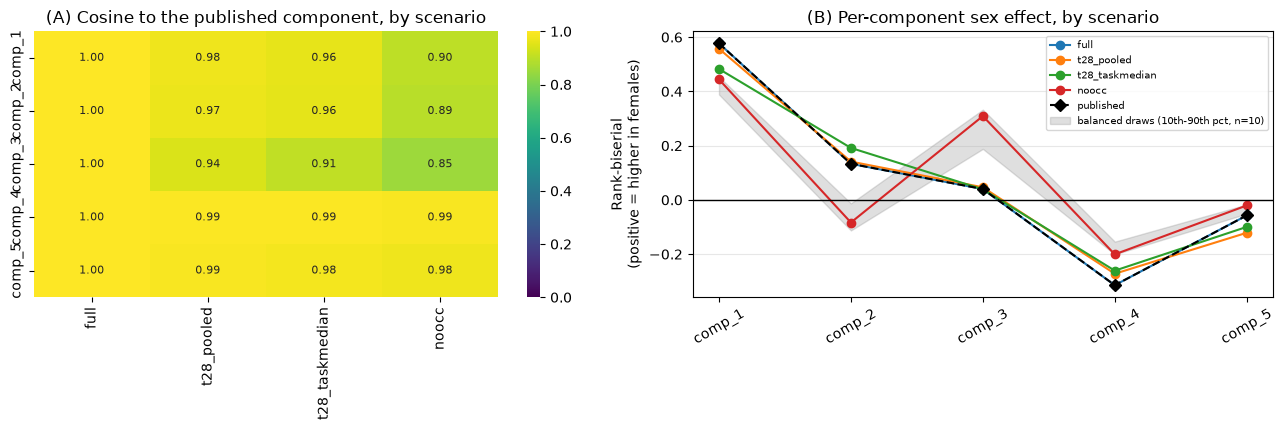

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

ax = axes[0]
order = [s for s in main_scenarios]
piv = comp_df[comp_df["scenario"].isin(order)].pivot(
    index="component", columns="scenario", values="cosine_to_published").reindex(COMP_LABELS)[order]
sns.heatmap(piv, ax=ax, cmap="viridis", vmin=0, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 8})
ax.set_title("(A) Cosine to the published component, by scenario")
ax.set_xlabel("")
ax.set_ylabel("")

ax = axes[1]
x = np.arange(len(COMP_LABELS))
for name in order:
    sub = comp_df[comp_df["scenario"] == name].set_index("component").reindex(COMP_LABELS)
    ax.plot(x, sub["rank_biserial"], marker="o", label=name)
pub_vals = [PUBLISHED_EFFECTS["effect_size"].get(lab, np.nan) for lab in COMP_LABELS]
ax.plot(x, pub_vals, marker="D", linestyle="--", color="black", label="published")
if len(bal_df):
    bsub = bal_summary.reindex(COMP_LABELS)
    ax.fill_between(x, bsub["r_lo"], bsub["r_hi"], color="grey", alpha=0.25,
                    label=f"balanced draws (10th-90th pct, n={N_BALANCED_DRAWS})")
ax.axhline(0, color="black", linewidth=1)
ax.set_xticks(x)
ax.set_xticklabels(COMP_LABELS, rotation=30)
ax.set_ylabel("Rank-biserial\n(positive = higher in females)")
ax.set_title("(B) Per-component sex effect, by scenario")
ax.legend(fontsize=7)
ax.grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "nb15_fig_scenarios.png", dpi=300, bbox_inches="tight")
plt.show()

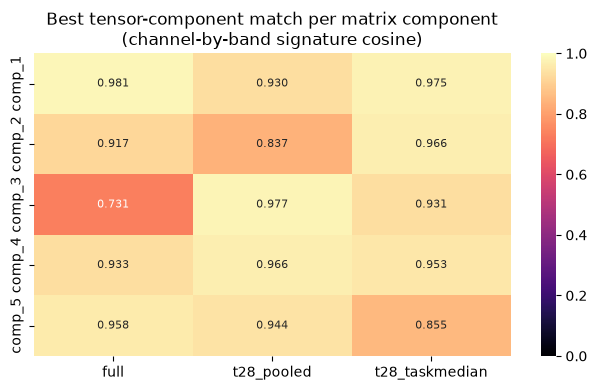

In [12]:
if have_parafac and len(corr_df):
    fig, ax = plt.subplots(1, 1, figsize=(6.5, 4))
    piv = corr_df.pivot(index="matrix_component", columns="matrix_fit",
                        values="cosine").reindex(COMP_LABELS)
    sns.heatmap(piv, ax=ax, cmap="magma", vmin=0, vmax=1, annot=True, fmt=".3f",
                annot_kws={"size": 8})
    ax.set_title("Best tensor-component match per matrix component\n"
                 "(channel-by-band signature cosine)")
    ax.set_xlabel("")
    ax.set_ylabel("")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "nb15_fig_parafac.png", dpi=300, bbox_inches="tight")
    plt.show()

## Summary for the response letter

In [13]:
lines = []


def w(s=""):
    """Print and record a summary line."""
    print(s)
    lines.append(s)


w("=" * 72)
w("NOTEBOOK 15 SUMMARY - task aggregation and coverage sensitivity")
w("=" * 72)
w("")
w("THE NINE EXCLUDED TASKS (for Section 4.10)")
for _, r in cov_df[~cov_df["complete"]].sort_values("n_participants").iterrows():
    w(f"  {r['task']} ({r['category']}): {r['n_participants']}/{N} participants")
w("")
w("RETAINED TASKS PER CATEGORY IN THE 28-TASK SET")
for cat in CATEGORIES:
    all_c = [t for t in TASKS_ALL if TASK_TO_CATEGORY[t] == cat]
    keep_c = [t for t in TASKS_28 if TASK_TO_CATEGORY[t] == cat]
    w(f"  {cat}: {len(keep_c)}/{len(all_c)}")
w("")
w("SCENARIO RESULTS (omnibus sex association)")
w(f"  published: stat {PUB_SEX_STAT:.4f}")
for _, r in sex_df.iterrows():
    w(f"  {r['scenario']:16s} ({int(r['n_features'])} features, n={int(r['n_participants'])}): "
      f"stat {r['omnibus_stat']:.4f}, p_perm {r['p_perm']:.4f}, p_FDR {r['p_fdr']:.4f}"
      f"{' *' if r['significant_fdr'] else ''}")
w("")
w("PER-COMPONENT SEX EFFECTS BY SCENARIO")
for name in main_scenarios:
    sub = comp_df[comp_df["scenario"] == name].set_index("component").reindex(COMP_LABELS)
    w(f"  {name}:")
    for lab in COMP_LABELS:
        w(f"    {lab}: r {sub.loc[lab, 'rank_biserial']:+.3f} "
          f"(p_FDR {sub.loc[lab, 'p_fdr']:.4f}), cosine {sub.loc[lab, 'cosine_to_published']:.3f}"
          f" | published r {sub.loc[lab, 'published_r']:+.3f}")
w("")
if len(bal_df):
    w(f"BALANCED DRAWS ({N_BALANCED_DRAWS} draws, {BALANCE_N} tasks per category, "
      f"{len(balance_categories)} categories)")
    for lab in COMP_LABELS:
        r = bal_summary.loc[lab]
        w(f"  {lab}: cosine median {r['median_cosine']:.3f}; r median {r['median_r']:+.3f} "
          f"[{r['r_lo']:+.3f}, {r['r_hi']:+.3f}], p<0.05 in {100 * r['frac_p_lt_05']:.0f}% of draws")
    w("")
if have_parafac and len(corr_df):
    w("TENSOR CORRESPONDENCE (channel-by-band signature cosine, best match)")
    for _, r in corr_df.iterrows():
        w(f"  {r['matrix_fit']:16s} {r['matrix_component']} -> "
          f"{r['best_tensor_component']}: {r['cosine']:.3f}")
    w("")
w("=" * 72)

with open(OUTPUT_DIR / "nb15_summary.txt", "w", encoding="utf-8") as fh:
    fh.write("\n".join(lines) + "\n")
print()
print(f"Saved {OUTPUT_DIR / 'nb15_summary.txt'}")

NOTEBOOK 15 SUMMARY - task aggregation and coverage sensitivity

THE NINE EXCLUDED TASKS (for Section 4.10)
  temporal_how_many_instruments1 (temporal): 82/86 participants
  parietal_2d_3d (parietal): 84/86 participants
  temporal_how_many_instruments2 (temporal): 84/86 participants
  prefrontal1 (frontal): 85/86 participants
  parietal_next_in_seq (parietal): 85/86 participants
  prefrontal2 (frontal): 85/86 participants
  temporal_how_many_instruments3 (temporal): 85/86 participants
  temporal_how_many_instruments4 (temporal): 85/86 participants
  image_happy_cute (temporal): 85/86 participants

RETAINED TASKS PER CATEGORY IN THE 28-TASK SET
  frontal: 4/6
  frontal_central: 6/6
  occipital: 1/1
  parietal: 7/9
  temporal: 10/15

SCENARIO RESULTS (omnibus sex association)
  published: stat 0.2742
  full             (350 features, n=86): stat 0.2742, p_perm 0.0002, p_FDR 0.0034 *
  t28_pooled       (350 features, n=86): stat 0.2310, p_perm 0.0004, p_FDR 0.0068 *
  t28_taskmedian   (35